# 1 IMPORT LIBRARY

In [2]:
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn import tree

Merupakan tahapan paling awal dalam menjalankan dataset, dimana ada import os(Menyediakan fungsi untuk berinteraksi dengan sistem operasi dan direktori), import pandas as pd(Memproses data dalam bentuk tabel menggunakan DataFrame), import seaborn as sns(Membuat grafik statistik, seperti boxplot, histogram, dan heatmap), import matplotlib.pyplot as plt(Mengatur dan menampilkan grafik.), StandardScaler(Menyediakan metode standardisasi data), LabelEncoder(Mengubah kategori menjadi kode bilangan bulat), train_test_split(Membagi dataset menjadi data latih dan data uji), cross_val_score(Mengevaluasi model melalui beberapa
pembagian data.), tree(Menyediakan algoritma pohon keputusan, termasuk regresi). Tanpa Output .


# 2 DATA LOADING

In [3]:
social_media = pd.read_csv("Social_media_impact.csv")

social_media.head()

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
0,STU_2024000,19,Female,Undergraduate,Snapchat,7.5,1.5,Smartphone,5.9,2,True,Always,20.0,73,2.73,Neutral
1,STU_2024001,19,Female,Undergraduate,Instagram,4.6,1.3,Smartphone,7.9,3,True,Sometimes,17.0,90,3.21,Beneficial
2,STU_2024002,17,Female,High School,TikTok,10.9,1.7,Smartphone,5.2,1,True,Frequently,18.0,70,3.00,Neutral
3,STU_2024003,16,Female,High School,YouTube,6.0,2.3,Tablet,7.6,4,True,Sometimes,15.0,82,3.42,Beneficial
4,STU_2024004,17,Male,High School,LinkedIn,3.3,2.6,Smartphone,7.6,4,True,Never,16.0,84,3.41,Beneficial


pd.read_csv(...) membaca file CSV menjadi sebuah DataFrame. "Social_media_impact.csv" adalah nama file dataset yang harus tersedia pada lokasi yang dapat diakses notebook, social_media adalah nama variabel yang menyimpan dataset 
dan head() menampilkan lima baris pertama sebagai sampel data. Output berupa tabel dengan kolom yang menggambarkan karakteristik penggunaan media sosial.

# 3 DATA UNDERSTANDING

# 3.1 Informasi dataset

In [4]:
social_media.info()

<class 'pandas.DataFrame'>
RangeIndex: 4500 entries, 0 to 4499
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Student_ID                   4500 non-null   str    
 1   Age                          4500 non-null   int64  
 2   Gender                       4500 non-null   str    
 3   Academic_Level               4500 non-null   str    
 4   Primary_Platform             4500 non-null   str    
 5   Daily_Usage_Hours            4500 non-null   float64
 6   Weekend_Extra_Hours          4500 non-null   float64
 7   Device_Type                  4500 non-null   str    
 8   Sleep_Duration_Hours         4500 non-null   float64
 9   Sleep_Quality_Score          4500 non-null   int64  
 10  Late_Night_Usage             4500 non-null   bool   
 11  Social_Comparison_Frequency  4500 non-null   str    
 12  Perceived_Stress_Score       4454 non-null   float64
 13  Mental_Health_Index          

Fungsi .info() menampilkan informasi struktural dataset, termasuk jumlah baris, jumlah kolom, tipe data, jumlah nilai yang tidak kosong, dan perkiraan penggunaan memori. 
Kolom numerik meliputi usia, durasi penggunaan, durasi tidur, skor kualitas tidur, skor stres, indeks kesehatan mental, dan GPA. Late_Night_Usage bertipe boolean, yaitu True atau False.
 

# 3.2 Statistik deskriptif

In [5]:
social_media.describe(include="all")

,Student_ID,Age,Gender,Academic_Level,Primary_Platform,Daily_Usage_Hours,Weekend_Extra_Hours,Device_Type,Sleep_Duration_Hours,Sleep_Quality_Score,Late_Night_Usage,Social_Comparison_Frequency,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Overall_Impact
count,4500,4500.000000,4500,4500,4500,4500.000000,4500.000000,4500,4500.000000,4500.000000,4500,4500,4454.000000,4500.000000,4415.000000,4500
unique,4500,NaN,4,3,7,NaN,NaN,3,NaN,NaN,2,5,NaN,NaN,NaN,3
top,STU_2024000,NaN,Female,Undergraduate,Instagram,NaN,NaN,Smartphone,NaN,NaN,True,Sometimes,NaN,NaN,NaN,Beneficial
freq,1,NaN,2234,2777,1453,NaN,NaN,3775,NaN,NaN,2644,1594,NaN,NaN,NaN,3681
mean,NaN,18.703333,NaN,NaN,NaN,5.295933,1.796844,NaN,6.701333,2.472000,NaN,NaN,13.512124,79.873111,3.429282,NaN
std,NaN,1.981182,NaN,NaN,NaN,2.604497,0.699245,NaN,1.189998,1.030484,NaN,NaN,7.072859,12.876044,0.392662,NaN
min,NaN,15.000000,NaN,NaN,NaN,0.900000,0.000000,NaN,3.000000,1.000000,NaN,NaN,0.000000,32.000000,1.900000,NaN
25%,NaN,17.000000,NaN,NaN,NaN,3.400000,1.300000,NaN,6.000000,2.000000,NaN,NaN,9.000000,72.000000,3.200000,NaN
50%,NaN,19.000000,NaN,NaN,NaN,4.700000,1.800000,NaN,6.800000,3.000000,NaN,NaN,13.000000,82.000000,3.460000,NaN
75%,NaN,20.000000,NaN,NaN,NaN,6.600000,2.300000,NaN,7.500000,3.000000,NaN,NaN,18.000000,89.000000,3.720000,NaN


Fungsi .describe() menghasilkan ringkasan statistik. Parameter include="all" meminta ringkasan untuk kolom numerik maupun kategorikal. Untuk data numerik, informasi yang ditampilkan mencakup count: jumlah nilai yang terisi,
mean: nilai rata-rata, std: standar deviasi atau ukuran penyebaran data, min: nilai minimuman, 25%: kuartil pertama, 50%: median, 75%: kuartil ketiga serta max: nilai maksimum.  
Untuk kolom kategorikal, informasi yang muncul antara lain unique (jumlah kategori unik), top (kategori paling sering muncul), dan freq (frekuensi kategori tersebut). 
Penggunaan media sosial dalam dataset cukup bervariasi. Statistik deskriptif memberikan gambaran awal, tetapi belum membuktikan bahwa penggunaan media sosial menyebabkan perubahan kesehatan mental.

# 3.3 Memeriksa missing value

In [6]:
missing_values = social_media.isnull().sum()
missing_values[missing_values > 0]

Perceived_Stress_Score      46
Academic_Performance_GPA    85
dtype: int64

isnull() memeriksa apakah setiap sel kosong, sum() menghitung jumlah nilai kosong pada setiap kolom, missing_values > 0 menyaring kolom yang memiliki setidaknya satu nilai kosong. Dari 4.500 baris, 
46 nilai mewakili sekitar 1,02% dari dataset untuk kolom stres, sedangkan 85 nilai mewakili sekitar 1,89% untuk kolom GPA. 

# 4 DATA CLEANING

# 4.1 Mengelompokkan kolom berdasarkan missing value

In [7]:
less = missing_values[missing_values < 1000].index
over = missing_values[missing_values >= 1000].index

Kode membagi kolom menjadi dua kelompok berdasarkan jumlah nilai kosong yakni less: kolom yang memiliki kurang dari 1.000 nilai kosong. over: kolom yang memiliki 1.000 nilai kosong atau lebih. 
Tidak ada output yang ditampilkan karena kode hanya menyimpan nama-nama kolom ke dalam variabel. Pada dataset ini, kedua kolom yang bermasalah hanya memiliki 46 dan 85 nilai kosong. Dengan demikian, 
keduanya masuk kelompok less. Tidak ada kolom yang masuk kelompok over, saya menetapkan ambang batas 1.000 nilai kosong untuk menentukan apakah kolom dipertahankan atau dihapus.

# 4.2 Mengisi missing value numerik dengan median

In [8]:
numeric_features = social_media[less].select_dtypes(
    include=['number']
).columns

social_media[numeric_features] = social_media[numeric_features].fillna(
    social_media[numeric_features].median()
)

social_media[less] mengambil kolom yang termasuk kelompok less. select_dtypes(include=['number']) memilih kolom bertipe numerik. columns mengambil nama kolom numerik tersebut. median() menghitung median setiap kolom. 
fillna(...) mengganti nilai kosong dengan median kolom masing-masing. Hasilnya dimasukkan kembali ke social_media. Median adalah nilai tengah setelah data diurutkan. 
Median sering digunakan untuk mengisi nilai kosong karena relatif tidak terpengaruh oleh nilai ekstrem dibandingkan rata-rata. Contoh sederhana Misalnya data GPA adalah 2.70, 3.00, NaN, 3.20, 3.40, 
Median dari nilai yang tersedia adalah 3.10, sehingga nilai kosong diganti menjadi 3.10. Tidak ada output.

# 4.3 Mengisi missing value kategorikal dengan modus

In [9]:
categorikal_features = social_media[less].select_dtypes(
    include=['str']
).columns

for column in categorikal_features:
    social_media[column] = social_media[column].fillna(
        social_media[column].mode()[0]
    )

select_dtypes(include=['str']) memilih kolom bertipe teks, for column in kategorikal_features menjalankan proses untuk setiap kolom kategorikal, mode() mencari nilai yang paling sering muncul, 
[0] mengambil modus pertama jika terdapat lebih dari satu modus, fillna(...) mengisi nilai kosong dengan modus tersebut.

# 4.4 Menghapus kolom dengan terlalu banyak missing value

In [10]:
df = social_media.drop(columns=over)

drop(columns=over) menghapus kolom yang termasuk kelompok over, hasilnya disimpan sebagai DataFrame baru bernama df. Variabel social_media tetap menjadi DataFrame awal yang telah mengalami pengisian nilai kosong. Variabel df digunakan sebagai dataset hasil pembersihan.

# 4.5 Memeriksa kembali missing value

In [11]:
missing_values = df.isnull().sum()
missing_values[missing_values > 0]

Series([], dtype: int64)

Series kosong berarti tidak ada kolom dengan nilai kosong yang terdeteksi pada DataFrame df, ini menunjukkan bahwa pemeriksaan missing value tidak menemukan nilai kosong yang tersisa pada tahap tersebut. 
Data kosong ditangani dengan median untuk kolom numerik dan modus untuk kolom kategorikal, sementara kolom dengan nilai kosong sangat banyak akan dihapus. 

# 5 OUTLIER DETECTION AND HANDLING

# 5.1 Visualisasi outlier sebelum penanganan

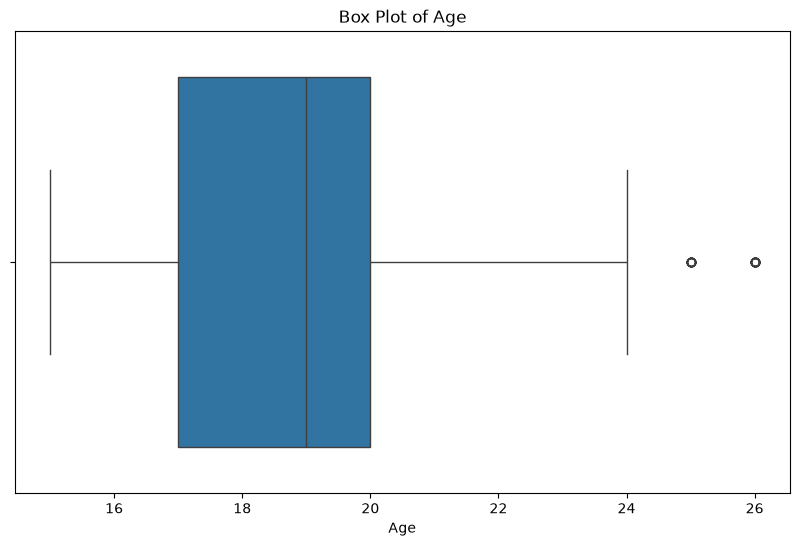

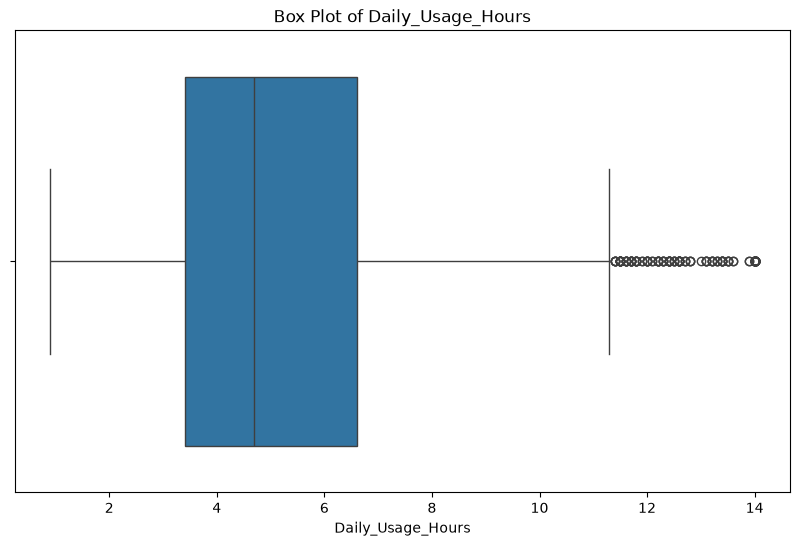

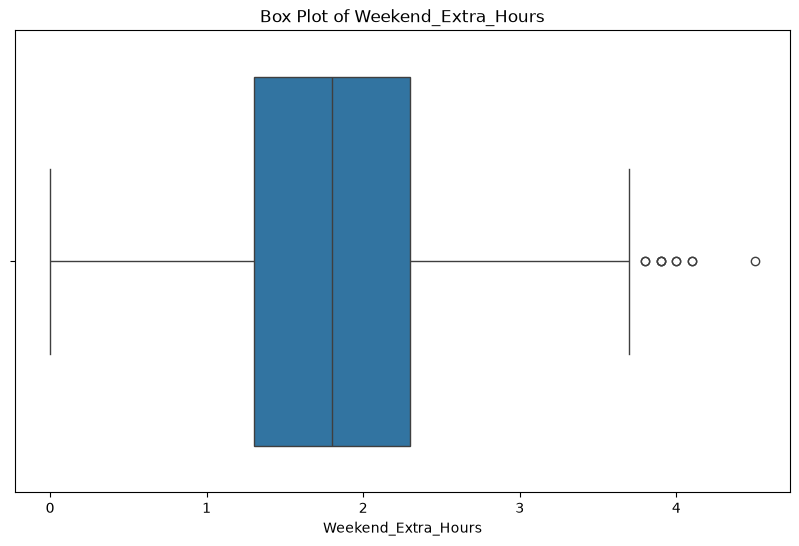

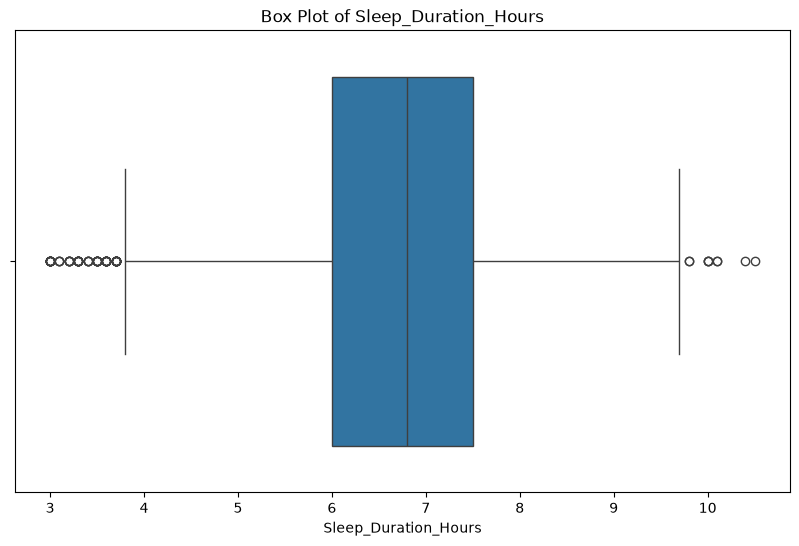

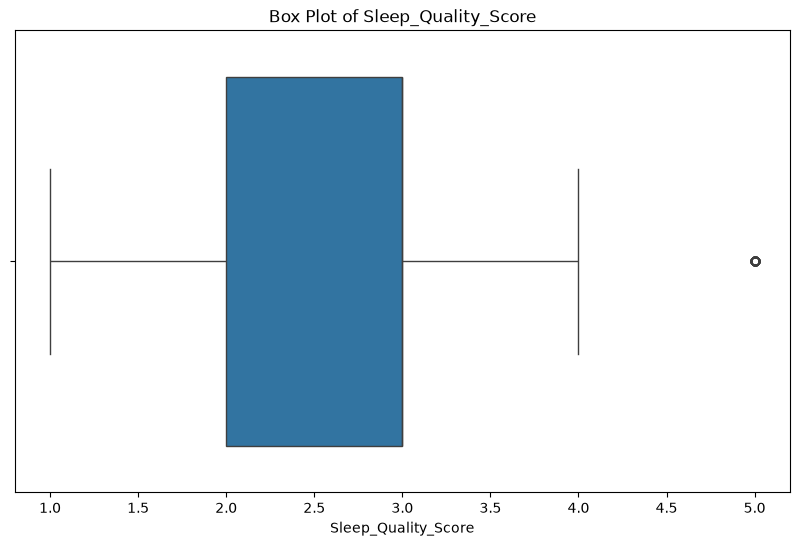

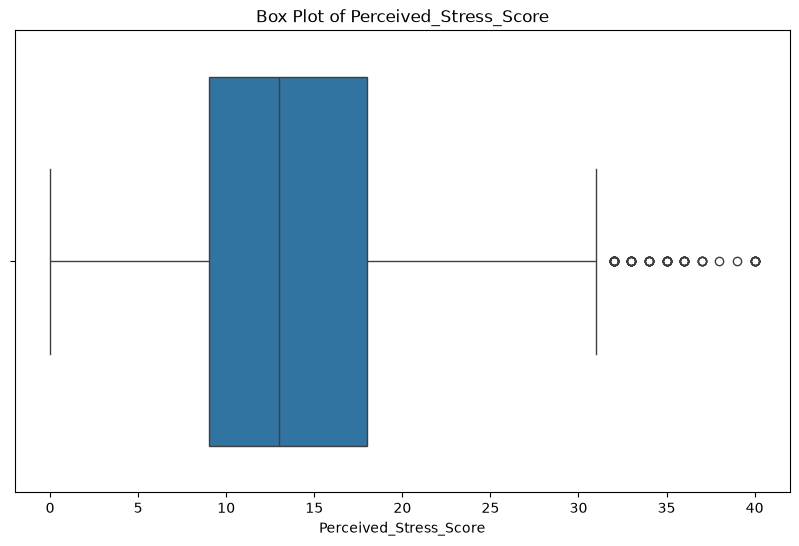

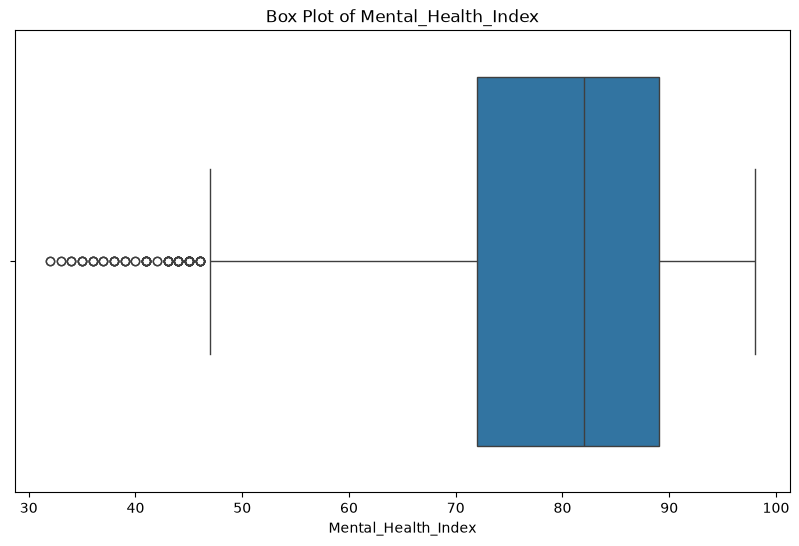

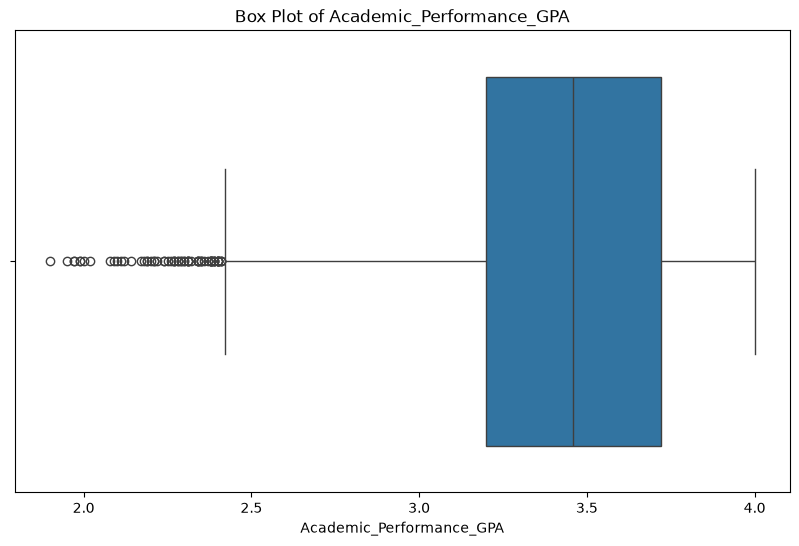

In [12]:
for feature in numeric_features:
    plt.figure(figsize=(10, 6))
    sns.boxplot(x=df[feature])
    plt.title(f'Box Plot of {feature}')
    plt.show()

for feature in numeric_features melakukan perulangan untuk setiap variabel numerik, plt.figure(figsize=(10, 6)) menentukan ukuran gambar, sns.boxplot(x=df[feature]) membuat boxplot untuk variabel yang sedang diperiksa,
plt.title(...) memberi judul sesuai nama kolom, plt.show() menampilkan grafik. Cara membaca output BloxPlot

# 5.2 Menyimpan data sebelum penanganan outlier

In [13]:
df_before = df.copy()

df.copy() membuat salinan DataFrame df sebelum proses penghapusan outlier. Salinan ini dinamai df_before dan nantinya digunakan untuk membandingkan kondisi data sebelum dan sesudah penanganan. 
Tidak ada output yang ditampilkan. Proses ini hanya menyimpan salinan data di memori.

# 5.3 Menghapus baris yang mengandung outlier dengan metode IQR

In [14]:
Q1 = df[numeric_features].quantile(0.25)
Q3 = df[numeric_features].quantile(0.75)

IQR = Q3 - Q1

condition = ~(
    (df[numeric_features] < (Q1 - 1.5 * IQR)) |
    (df[numeric_features] > (Q3 + 1.5 * IQR))
).any(axis=1)

df_filtered_numeric = df.loc[condition, numeric_features]

categorical_features = df.select_dtypes(
    include=['str']
).columns

df = pd.concat(
    [df_filtered_numeric, df.loc[condition, categorical_features]],
    axis=1
)

IQR (Interquartile Range) adalah selisih kuartil ketiga dengan kuartil pertama, Batas bawah dan batas atas dihitung dengan rumus Batas Bawah = Q1 – 1.5(IQR), Batas Atas = Q2+1.5(IQR). Nilai di luar batas tersebut dianggap kandidat outlier. 
quantile(0.25) menghitung Q1, quantile(0.75) menghitung Q3, IQR = Q3 - Q1 menghitung rentang antarkuartil, Kondisi membandingkan seluruh variabel numerik dengan batas IQR, any(axis=1) memeriksa apakah suatu baris memiliki setidaknya satu nilai 
di luar batas pada salah satu kolom numerik, Operator ~ membalik kondisi sehingga baris yang dipertahankan adalah baris yang tidak memiliki kandidat outlier pada kolom-kolom numerik tersebut, df.loc[condition, ...] 
mengambil baris yang lolos dari pemeriksaan, pd.concat(..., axis=1) menggabungkan kembali kolom numerik dan kategorikal dari baris yang sama. Hasilnya Ddri data awal sebanyak 4.500 baris, hasil yang ditampilkan pada tahap berikutnya memiliki 4.122 baris. 
Berarti ada 378 baris yang tidak dipertahankan dalam proses penyaringan ini. Dimana (378/4500)x100%=8,4, Jadi ekitar 8,4% baris awal tidak digunakan setelah proses tersebut.

# 5.4 Membandingkan boxplot sebelum dan sesudah penanganan

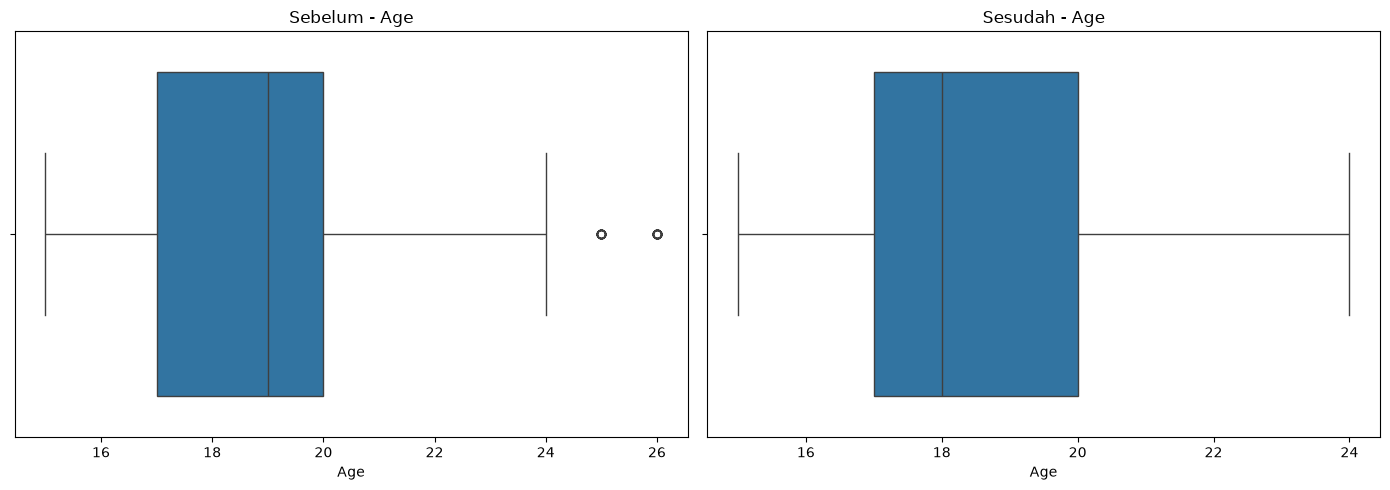

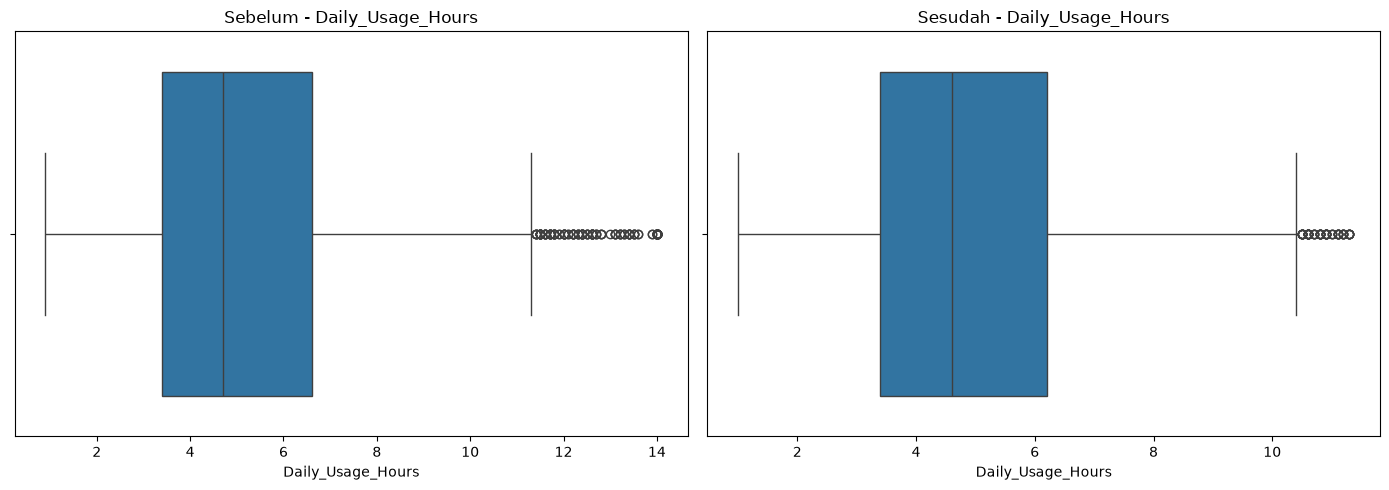

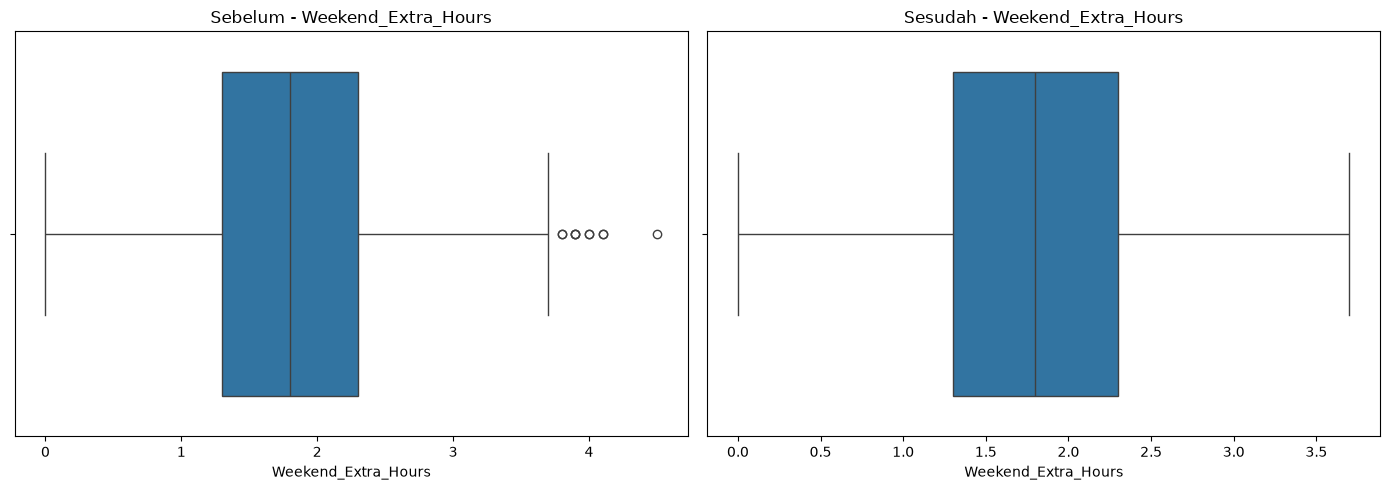

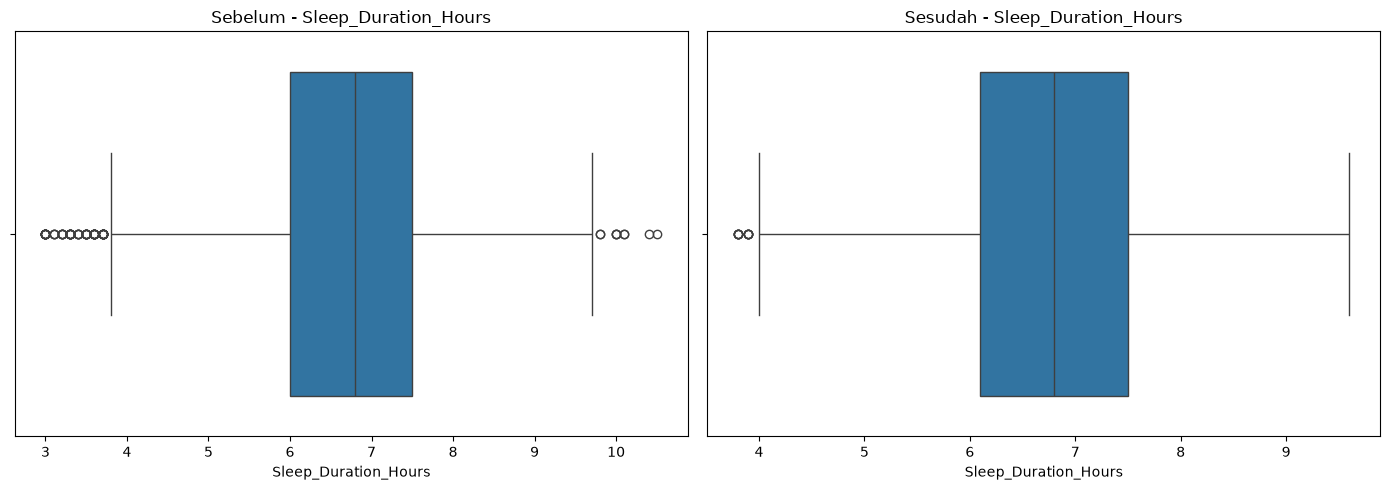

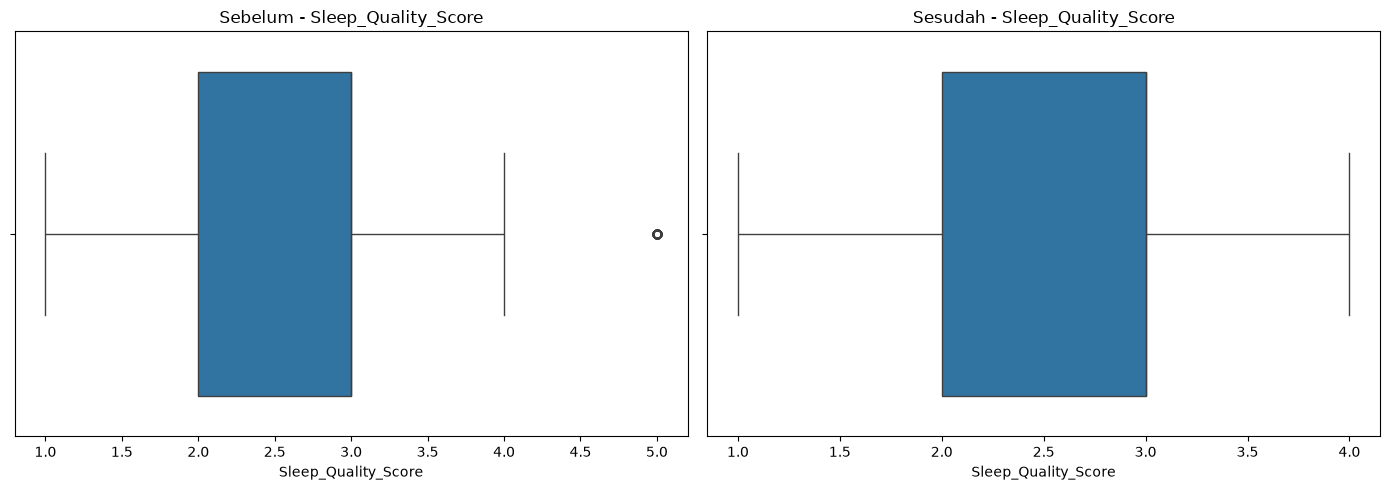

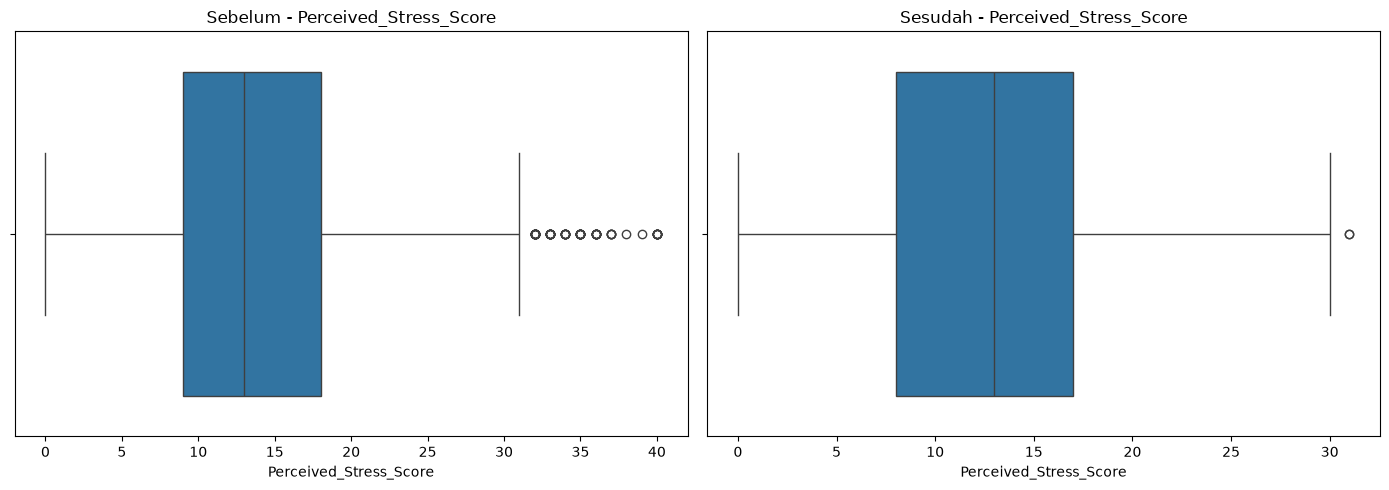

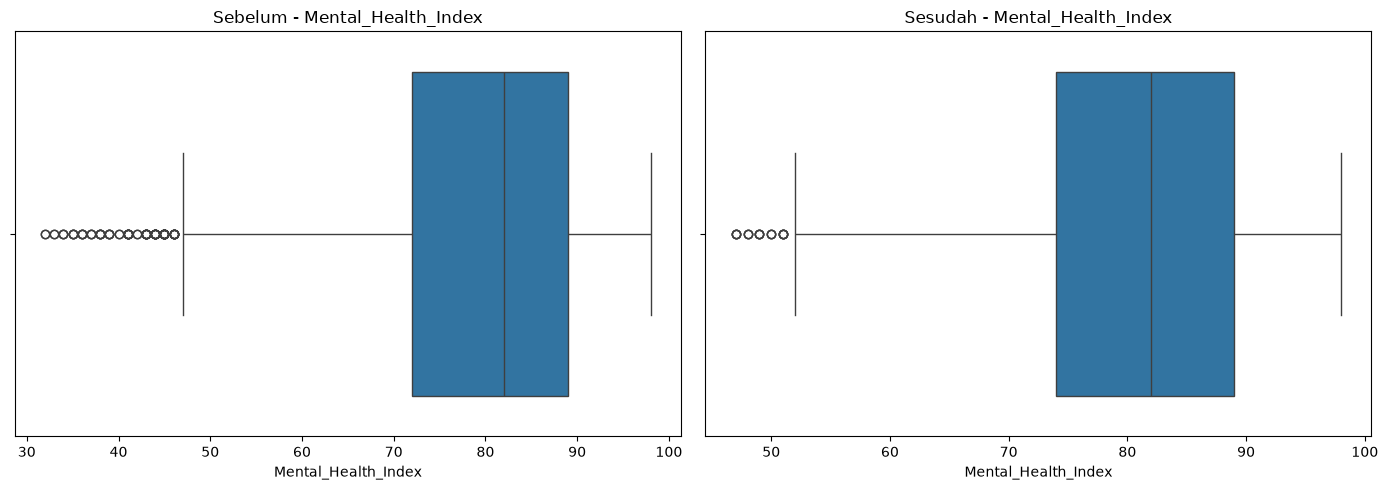

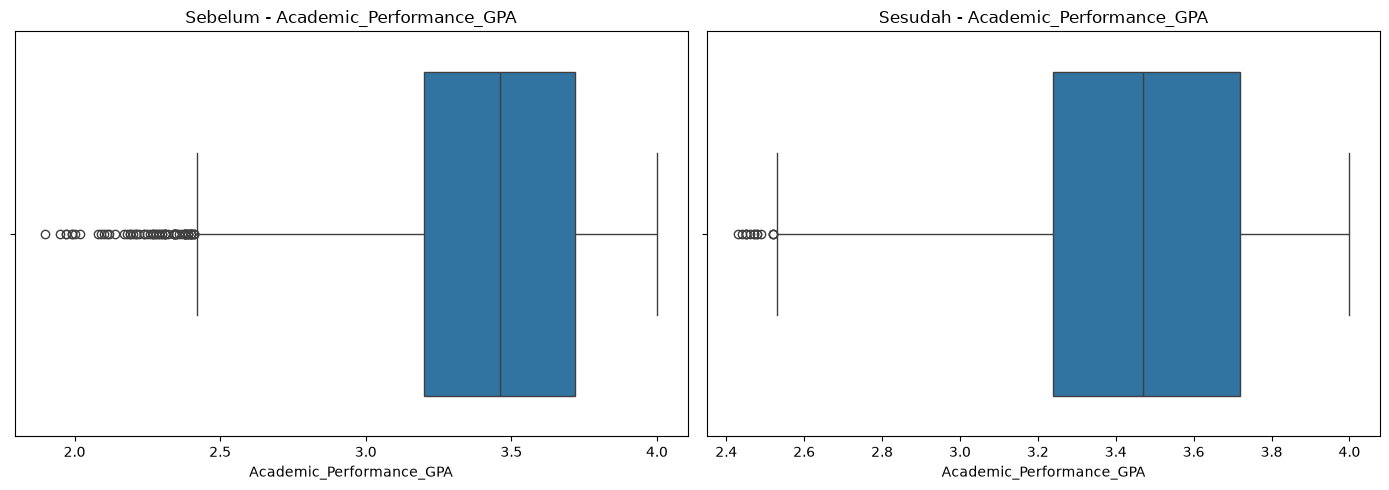

In [15]:
for feature in numeric_features:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    sns.boxplot(x=df_before[feature], ax=axes[0])
    axes[0].set_title(f'Sebelum - {feature}')

    sns.boxplot(x=df[feature], ax=axes[1])
    axes[1].set_title(f'Sesudah - {feature}')

    plt.tight_layout()
    plt.show()

plt.subplots(1, 2) membuat dua grafik dalam satu baris, grafik kiri menggunakan df_before, yaitu data sebelum penyaringan, grafik kanan menggunakan df, yaitu data setelah penyaringan, tight_layout() mengatur jarak antarelemen agar lebih rapi. 
erdapat 8 gambar perbandingan, masing-masing terdiri dari boxplot sebelum dan sesudah. Tujuannya adalah melihat apakah nilai ekstrem berkurang setelah penyaringan IQR. Grafik setelah penanganan semestinya tidak lagi memperlihatkan nilai 
di luar batas IQR yang digunakan untuk menyaring baris tersebut.

# 5.5 Metode alternatif: mengganti outlier Age dengan median

In [16]:
print("Median sebelum penggantian:", df['Age'].median())

Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1

median = df['Age'].median()

df['Age'] = df['Age'].apply(
    lambda x: median
    if x < (Q1 - 1.5 * IQR) or x > (Q3 + 1.5 * IQR)
    else x
)

print("Data Age setelah penggantian outlier:")
print(df['Age'].head(10))

Median sebelum penggantian: 18.0
Data Age setelah penggantian outlier:
0     19
1     19
2     17
3     16
4     17
5     16
6     20
8     18
9     18
10    15
Name: Age, dtype: int64


Kode ini mencoba pendekatan lain untuk menangani outlier pada kolom Age. df['Age'].median() mencari median usia, Q1, Q3, dan IQR digunakan untuk menentukan batas kandidat outlier, apply(...) memeriksa setiap nilai usia, 
lambda mengganti nilai di luar batas dengan median dan mempertahankan nilai yang masih berada di dalam batas, head(10) menampilkan sepuluh nilai usia pertama.

# 5.6 Metode alternatif: capping outlier Age

In [17]:
Q1 = df['Age'].quantile(0.25)
Q3 = df['Age'].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df['Age'] = df['Age'].apply(
    lambda x: lower_bound if x < lower_bound
    else upper_bound if x > upper_bound
    else x
)

df['Age']

0       19
1       19
2       17
3       16
4       17
        ..
4495    16
4496    19
4497    19
4498    16
4499    24
Name: Age, Length: 4122, dtype: int64

Metode capping berbeda dari penggantian median, nilai yang lebih kecil dari batas bawah diganti dengan batas bawah, nilai yang lebih besar dari batas atas diganti dengan batas atas, nilai di dalam batas tetap dipertahankan.

# 6 MENANGANI DUPLIKASI DATA

# 6.1 Mengidentifikasi baris duplikat

In [18]:
duplicates = df.duplicated()

print("Baris duplikat:")
print(df[duplicates])

Baris duplikat:
Empty DataFrame
Columns: [Age, Daily_Usage_Hours, Weekend_Extra_Hours, Sleep_Duration_Hours, Sleep_Quality_Score, Perceived_Stress_Score, Mental_Health_Index, Academic_Performance_GPA, Student_ID, Gender, Academic_Level, Primary_Platform, Device_Type, Social_Comparison_Frequency, Overall_Impact]
Index: []


df.duplicated() memeriksa baris yang memiliki isi sama dengan baris sebelumnya, Hasilnya berupa nilai boolean: True untuk duplikat dan False untuk baris yang tidak terduplikasi, df[duplicates] hanya menampilkan baris yang ditandai sebagai
duplikat. Secara default, Pandas mempertahankan kemunculan pertama dan menandai kemunculan berikutnya sebagai duplikat.


# 6.2 Menghapus baris duplikat

In [19]:
df = df.drop_duplicates()

print("DataFrame setelah menghapus duplikat:")
print(df)

DataFrame setelah menghapus duplikat:
      Age  Daily_Usage_Hours  Weekend_Extra_Hours  Sleep_Duration_Hours  \
0      19                7.5                  1.5                   5.9   
1      19                4.6                  1.3                   7.9   
2      17               10.9                  1.7                   5.2   
3      16                6.0                  2.3                   7.6   
4      17                3.3                  2.6                   7.6   
...   ...                ...                  ...                   ...   
4495   16                5.8                  1.2                   7.8   
4496   19                3.8                  3.0                   6.6   
4497   19                7.7                  1.1                   6.0   
4498   16                4.6                  3.3                   7.1   
4499   24                1.8                  2.1                   6.8   

      Sleep_Quality_Score  Perceived_Stress_Score  Mental_Hea

drop_duplicates() menghapus baris duplikat, Hasilnya disimpan kembali ke variabel df, print(df) menampilkan DataFrame hasilnya.TTabel hasil menampilkan data dengan kolom numerik dan kategorikal, termasuk Age, Daily_Usage_Hours,
Mental_Health_Index, Academic_Performance_GPA, Student_ID, dan Overall_Impact. Jumlah baris yang terlihat adalah 4.122. Karena pemeriksaan sebelumnya tidak menemukan duplikasi, perintah penghapusan tidak diharapkan mengurangi jumlah baris lagi.
 

# 7 IDENTIFIKASI TIPE DATA DAN ENCODING

# 7.1 Mengidentifikasi kolom kategorikal

In [20]:
category_features = df.select_dtypes(
    include=['str']
).columns

df[category_features]

,Student_ID,Gender,Academic_Level,Primary_Platform,Device_Type,Social_Comparison_Frequency,Overall_Impact
0,STU_2024000,Female,Undergraduate,Snapchat,Smartphone,Always,Neutral
1,STU_2024001,Female,Undergraduate,Instagram,Smartphone,Sometimes,Beneficial
2,STU_2024002,Female,High School,TikTok,Smartphone,Frequently,Neutral
3,STU_2024003,Female,High School,YouTube,Tablet,Sometimes,Beneficial
4,STU_2024004,Male,High School,LinkedIn,Smartphone,Never,Beneficial
...,...,...,...,...,...,...,...
4495,STU_2028495,Male,High School,YouTube,Smartphone,Sometimes,Beneficial
4496,STU_2028496,Female,Undergraduate,LinkedIn,Smartphone,Frequently,Beneficial
4497,STU_2028497,Male,Undergraduate,Instagram,Smartphone,Frequently,Beneficial
4498,STU_2028498,Male,High School,LinkedIn,Laptop/PC,Sometimes,Beneficial


select_dtypes(include=['str']) memilih kolom bertipe teks, columns mengambil nama kolom kategorikal, df[category_features] menampilkan seluruh kolom tersebut.

# 7.2 One-Hot Encoding

In [21]:
df_one_hot = pd.get_dummies(
    df,
    columns=category_features
)

df_one_hot

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Student_ID_STU_2024000,Student_ID_STU_2024001,...,Device_Type_Smartphone,Device_Type_Tablet,Social_Comparison_Frequency_Always,Social_Comparison_Frequency_Frequently,Social_Comparison_Frequency_Never,Social_Comparison_Frequency_Rarely,Social_Comparison_Frequency_Sometimes,Overall_Impact_Beneficial,Overall_Impact_Negative,Overall_Impact_Neutral
0,19,7.5,1.5,5.9,2,20.0,73,2.73,True,False,...,True,False,True,False,False,False,False,False,False,True
1,19,4.6,1.3,7.9,3,17.0,90,3.21,False,True,...,True,False,False,False,False,False,True,True,False,False
2,17,10.9,1.7,5.2,1,18.0,70,3.00,False,False,...,True,False,False,True,False,False,False,False,False,True
3,16,6.0,2.3,7.6,4,15.0,82,3.42,False,False,...,False,True,False,False,False,False,True,True,False,False
4,17,3.3,2.6,7.6,4,16.0,84,3.41,False,False,...,True,False,False,False,True,False,False,True,False,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4495,16,5.8,1.2,7.8,3,11.0,79,2.85,False,False,...,True,False,False,False,False,False,True,True,False,False
4496,19,3.8,3.0,6.6,3,9.0,83,3.37,False,False,...,True,False,False,True,False,False,False,True,False,False
4497,19,7.7,1.1,6.0,2,13.0,73,3.16,False,False,...,True,False,False,True,False,False,False,True,False,False
4498,16,4.6,3.3,7.1,3,22.0,87,3.50,False,False,...,False,False,False,False,False,False,True,True,False,False


pd.get_dummies() mengubah setiap kategori menjadi kolom indikator biner. Nilai 1 menandakan kategori yang dimiliki baris tersebut, sedangkan 0 menandakan kategori yang tidak dimiliki. 
One-Hot Encoding cocok untuk fitur kategorikal yang tidak memiliki urutan alami, seperti jenis perangkat atau platform media sosial. Namun, hasil df_one_hot tidak digunakan untuk pelatihan model pada alur notebook ini; model berikutnya menggunakan df_lencoder.

# 7.3 Label Encoding

In [22]:
label_encoder = LabelEncoder()

df_lencoder = pd.DataFrame(df)

for col in category_features:
    df_lencoder[col] = label_encoder.fit_transform(df[col])

df_lencoder

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Student_ID,Gender,Academic_Level,Primary_Platform,Device_Type,Social_Comparison_Frequency,Overall_Impact
0,19,7.5,1.5,5.9,2,20.0,73,2.73,0,0,2,3,1,0,2
1,19,4.6,1.3,7.9,3,17.0,90,3.21,1,0,2,0,1,4,0
2,17,10.9,1.7,5.2,1,18.0,70,3.00,2,0,0,4,1,1,2
3,16,6.0,2.3,7.6,4,15.0,82,3.42,3,0,0,6,2,4,0
4,17,3.3,2.6,7.6,4,16.0,84,3.41,4,1,0,1,1,2,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4495,16,5.8,1.2,7.8,3,11.0,79,2.85,4117,1,0,6,1,4,0
4496,19,3.8,3.0,6.6,3,9.0,83,3.37,4118,0,2,1,1,1,0
4497,19,7.7,1.1,6.0,2,13.0,73,3.16,4119,1,2,0,1,1,0
4498,16,4.6,3.3,7.1,3,22.0,87,3.50,4120,1,0,1,0,4,0


LabelEncoder() membuat objek encoder, pd.DataFrame(df) membuat salinan DataFrame untuk hasil encoding, perulangan memproses setiap kolom kategorikal.,fit_transform() mempelajari kategori unik dan mengubahnya menjadi bilangan bulat.
Apa perbedaan Label Encoding dan One-Hot Encoding? Label Encoding: satu kolom kategori diubah menjadi angka sementara One-Hot Encoding: satu kolom kategori dipecah menjadi beberapa kolom indikator. Label Encoding membuat tabel lebih ringkas. Namun, angka kategori tidak selalu menunjukkan tingkatan atau jarak yang bermakna. Misalnya, kode 0 untuk satu platform dan 6 untuk platform lain tidak berarti platform kedua memiliki nilai enam kali lebih tinggi.


# 8. EXPLORATORY DATA ANALYSIS (EDA)

# 8.1 Melihat data hasil Label Encoding

In [23]:
df_lencoder.head()

,Age,Daily_Usage_Hours,Weekend_Extra_Hours,Sleep_Duration_Hours,Sleep_Quality_Score,Perceived_Stress_Score,Mental_Health_Index,Academic_Performance_GPA,Student_ID,Gender,Academic_Level,Primary_Platform,Device_Type,Social_Comparison_Frequency,Overall_Impact
0,19,7.5,1.5,5.9,2,20.0,73,2.73,0,0,2,3,1,0,2
1,19,4.6,1.3,7.9,3,17.0,90,3.21,1,0,2,0,1,4,0
2,17,10.9,1.7,5.2,1,18.0,70,3.00,2,0,0,4,1,1,2
3,16,6.0,2.3,7.6,4,15.0,82,3.42,3,0,0,6,2,4,0
4,17,3.3,2.6,7.6,4,16.0,84,3.41,4,1,0,1,1,2,0


Tabel memperlihatkan fitur numerik asli seperti usia, durasi penggunaan, dan indeks kesehatan mental, bersamaan dengan fitur kategorikal yang sudah diubah menjadi angka. Data sudah memiliki representasi numerik untuk kategori. Ini memudahkan pemeriksaan korelasi numerik dan penggunaan model yang menerima input angka. Namun, nilai kode kategori seperti Gender = 0 tidak boleh diartikan sebagai ukuran kuantitatif. Nilai itu hanya label yang diberikan encoder.

# 8.2 Memeriksa missing value setelah encoding

In [24]:
missing_values = df_lencoder.isnull().sum()
missing_percentage = (missing_values / len(df_lencoder)) * 100

missing_data = pd.DataFrame({
    'Missing Values': missing_values,
    'Percentage': missing_percentage
}).sort_values(by='Missing Values', ascending=False)

missing_data[missing_data['Missing Values'] > 0]

,Missing Values,Percentage


Kode menghitung dua informasi Jumlah nilai kosong setiap kolom serta persentase nilai kosong dibandingkan jumlah seluruh baris. Persentasi missing = jumlah missing/jumlah baris x 100%. Kemudian, informasi tersebut disusun menjadi tabel missing_data dan diurutkan berdasarkan jumlah nilai kosong.

# 8.3 Histogram semua variabel

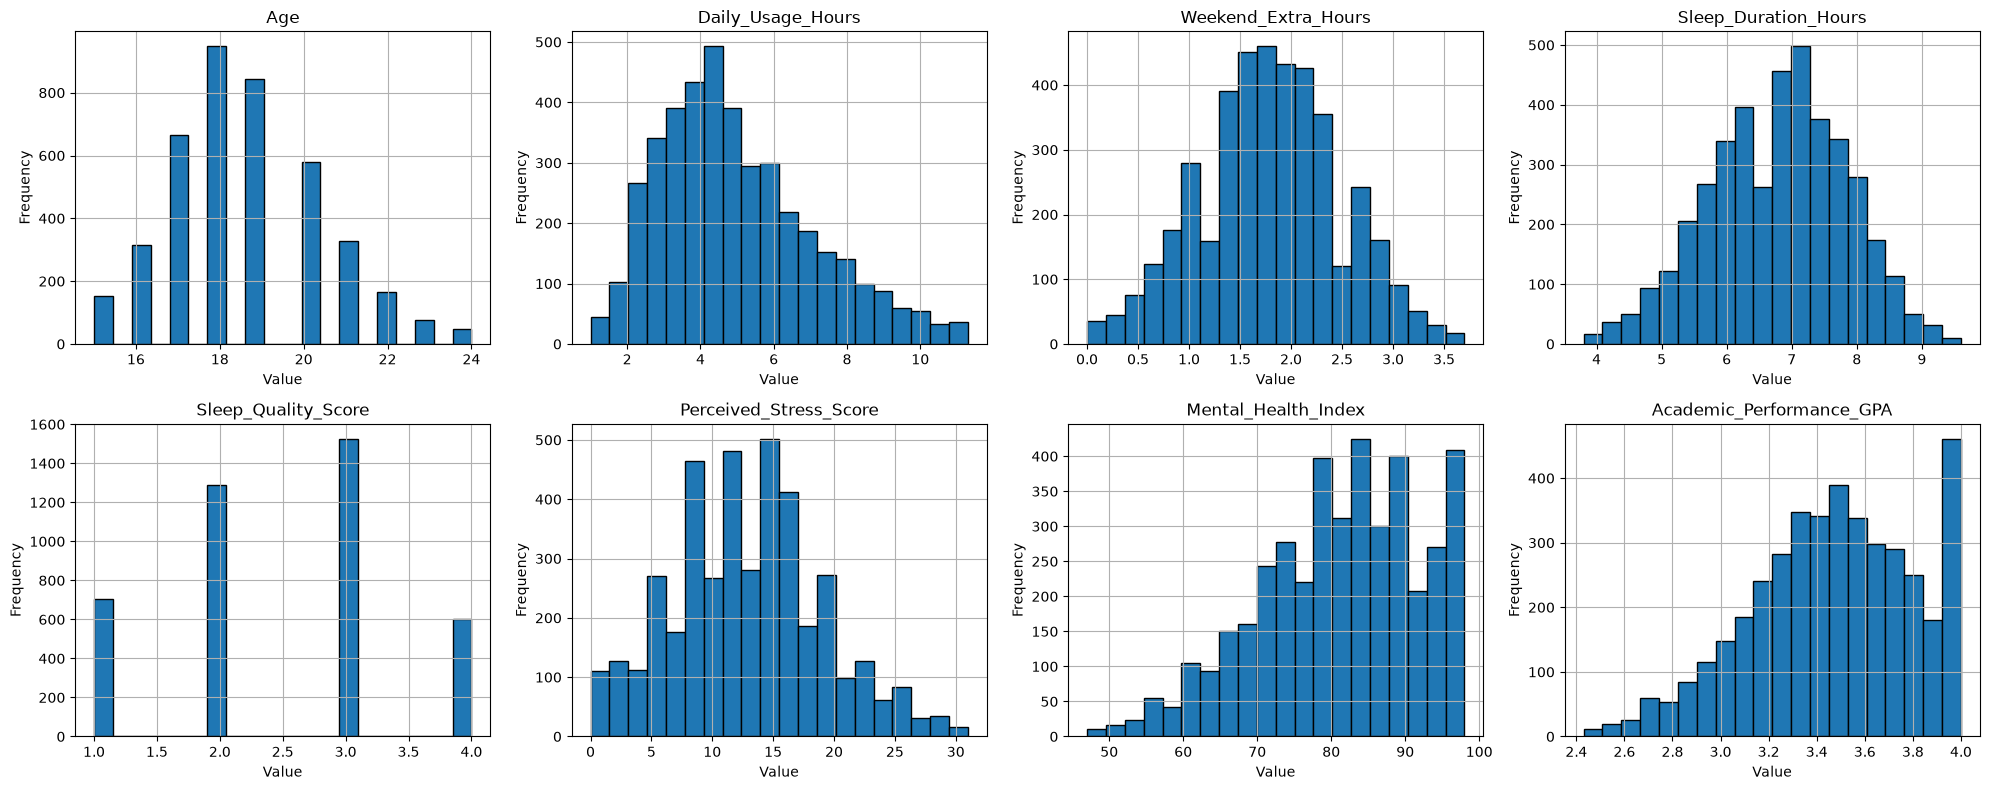

In [25]:
num_vars = df.select_dtypes(include=['number']).shape[1]

n_cols = 4
n_rows = -(-num_vars // n_cols)

fig, axes = plt.subplots(
    n_rows, n_cols,
    figsize=(20, n_rows * 4)
)

axes = axes.flatten()

numeric_columns = df.select_dtypes(include=['number']).columns

for i, column in enumerate(numeric_columns):
    df[column].hist(
        ax=axes[i],
        bins=20,
        edgecolor='black'
    )
    axes[i].set_title(column)
    axes[i].set_xlabel('Value')
    axes[i].set_ylabel('Frequency')

for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

df.shape[1] menghitung jumlah kolom dalam df, n_cols = 4 menetapkan empat grafik per baris, (-num_vars // n_cols) merupakan cara menghitung pembulatan ke atas untuk menentukan jumlah baris grafik, plt.subplots() membuat kumpulan grafik, flatten() mengubah susunan objek sumbu menjadi array satu dimensi agar mudah diakses, enumerate(df.columns) melakukan perulangan pada setiap nama kolom, hist() membuat histogram dengan 20 kelompok atau bins, set_title() memberi judul sesuai nama kolom, erulangan terakhir menghapus area grafik kosong yang tidak terpakai. Setiap grafik menggambarkan frekuensi nilai pada satu kolom, misalnya distribusi usia, jam penggunaan media sosial, dan skor kesehatan mental. Sumbu X menunjukkan nilai variabel, Sumbu Y menunjukkan banyaknya observasi pada rentang nilai tersebut, batang yang tinggi menunjukkan nilai yang relatif sering muncul, Distribusi yang simetris berbeda dari distribusi yang menceng ke kiri atau kanan.

# 8.4 Histogram variabel tertentu

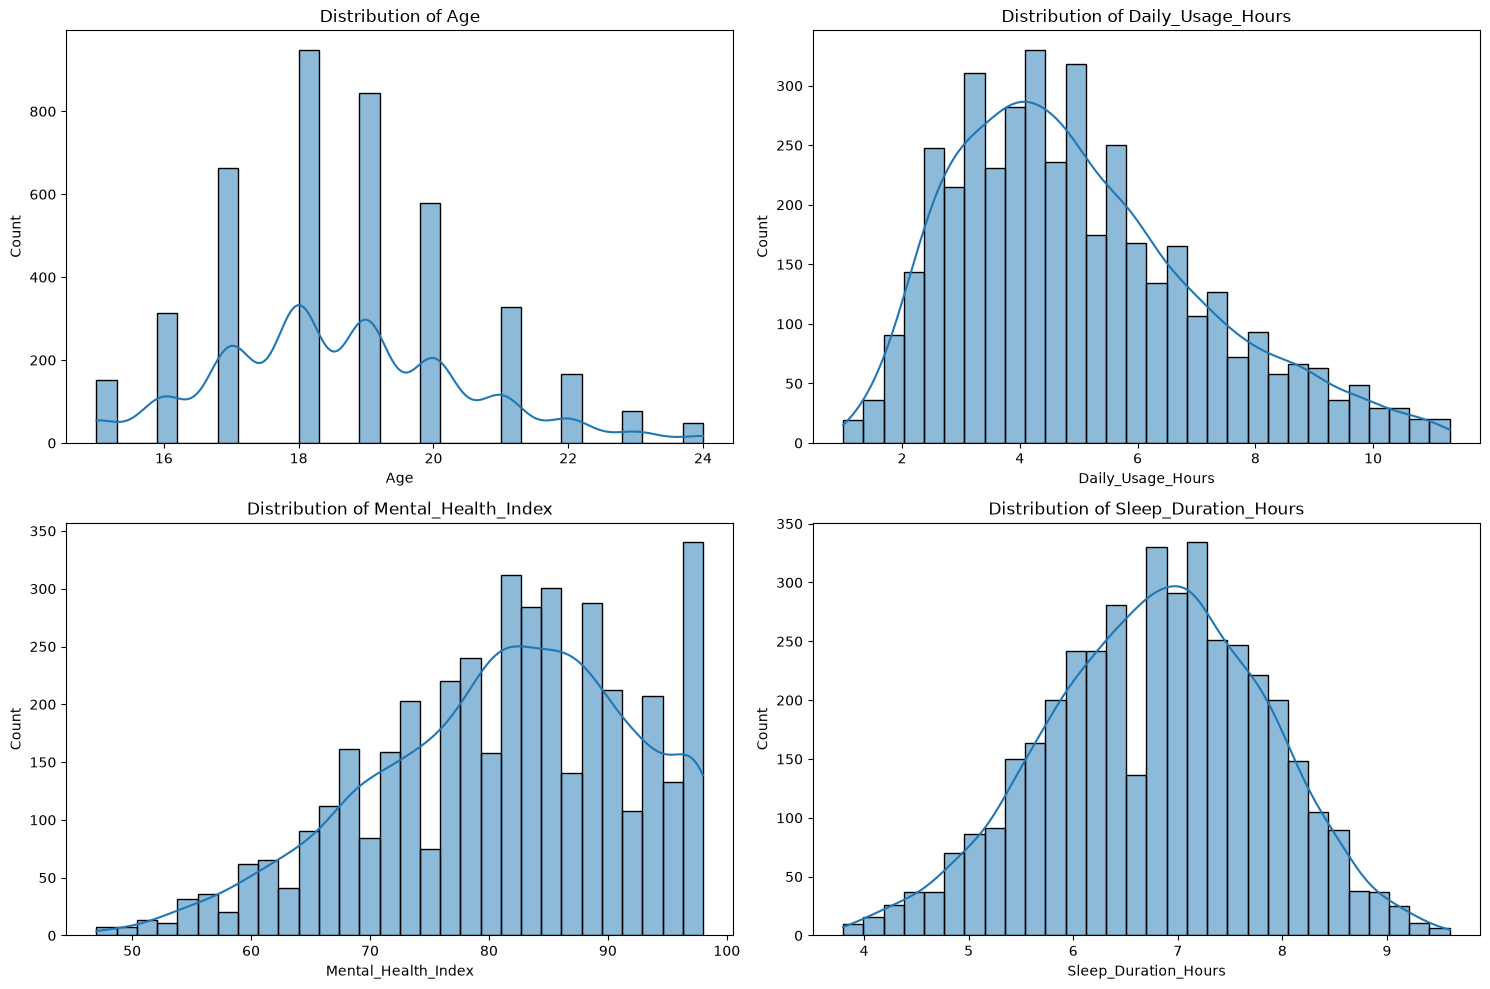

In [26]:
columns_to_plot = [
    'Age',
    'Daily_Usage_Hours',
    'Mental_Health_Index',
    'Sleep_Duration_Hours'
]

plt.figure(figsize=(15, 10))

for i, column in enumerate(columns_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.histplot(df[column], kde=True, bins=30)
    plt.title(f'Distribution of {column}')

plt.tight_layout()
plt.show()

plt.subplot(2, 2, i) menempatkan empat grafik dalam susunan dua baris dan dua kolom. parameter kde=True menambahkan kurva KDE (Kernel Density Estimation) untuk memperlihatkan perkiraan bentuk distribusi data secara lebih halus. Apakah durasi tidur memiliki pola distribusi yang relatif simetris? grafik tersebut mendeskripsikan distribusi, bukan hubungan sebab-akibat. Untuk menyimpulkan apakah penggunaan media sosial berkaitan dengan kesehatan mental, dibutuhkan analisis hubungan antarvariabel.

# 8.5 Heatmap korelasi antarvariabel

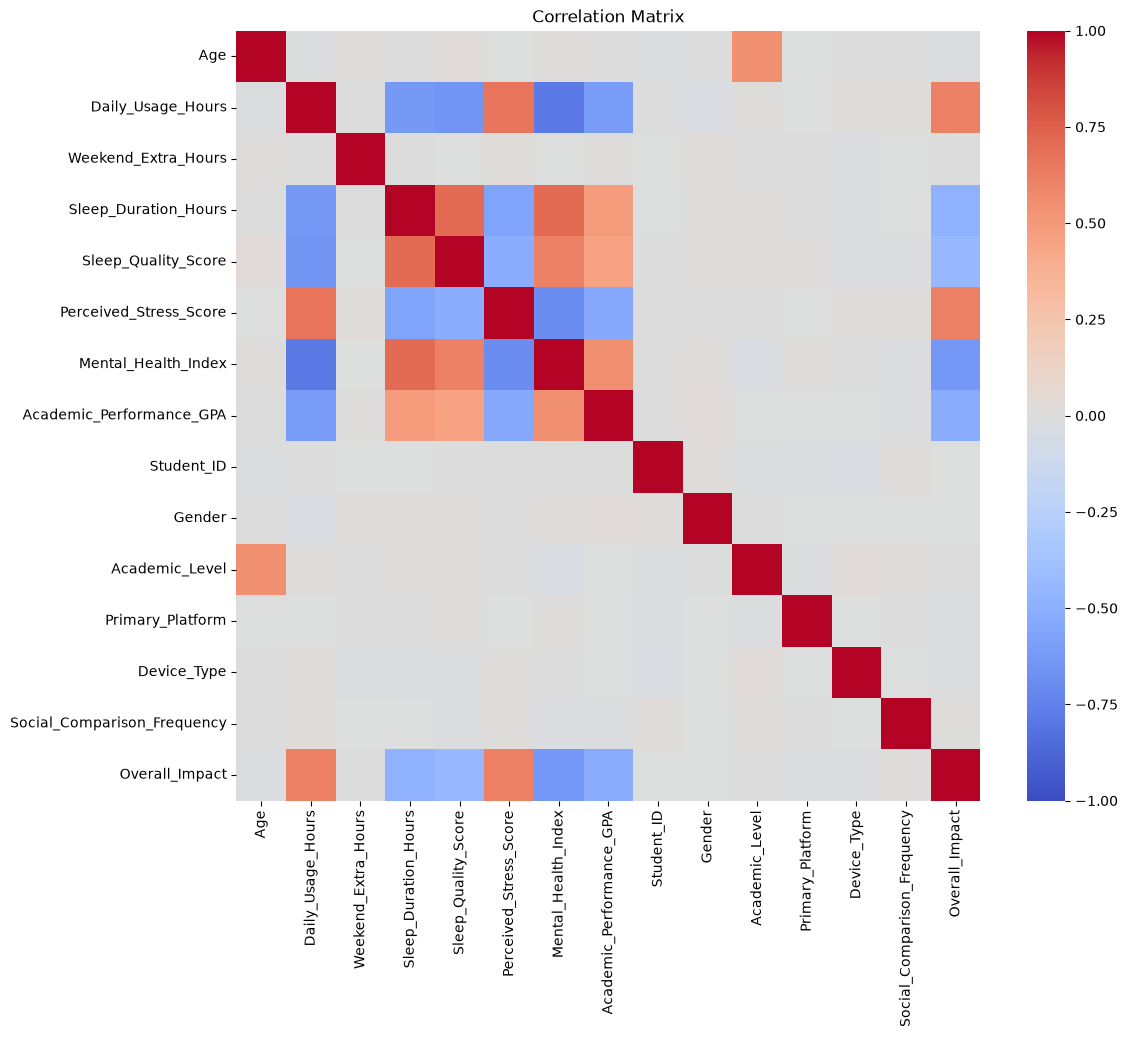

In [27]:
plt.figure(figsize=(12, 10))

correlation_matrix = df_lencoder.corr()

sns.heatmap(
    correlation_matrix,
    annot=False,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Matrix')
plt.show()

df_lencoder.corr() menghitung matriks korelasi antarvariabel numerik. sns.heatmap() menampilkan korelasi sebagai peta warna. annot=False menyembunyikan angka korelasi di setiap sel. cmap='coolwarm' menentukan gradasi warna. vmin=-1 dan vmax=1 menetapkan rentang korelasi yang ditampilkan. Koefisien korelasi berada pada rentang -1sampai 1
Mendekati +1 Hubungan linear positif yang kuat
Mendekati 0 Hubungan linear yang lemah atau tidak terlihat
Mendekati -1 Hubungan linear negatif yang kuat
Contohnya, korelasi positif berarti kenaikan suatu variabel cenderung disertai kenaikan variabel lainnya. Korelasi negatif berarti kenaikan satu variabel cenderung disertai penurunan variabel lainnya.

 

# 8.6 Korelasi terhadap target Mental_Health_Index

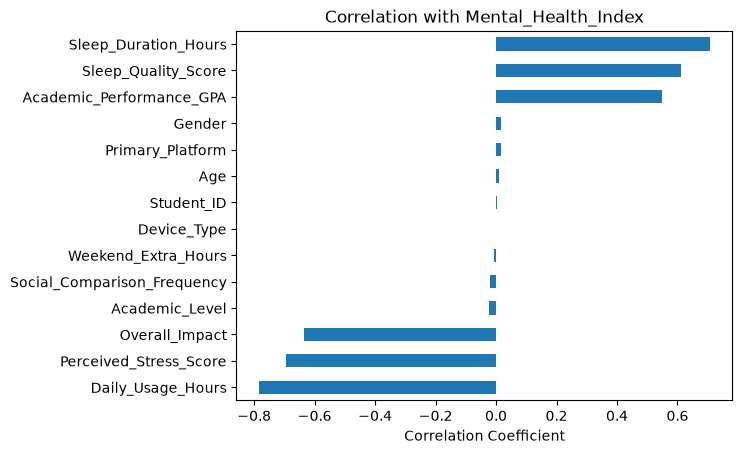

In [28]:
target_corr = (
    df_lencoder.corr()['Mental_Health_Index']
    .drop('Mental_Health_Index')
    .sort_values()
)

target_corr.plot(kind='barh')
plt.title('Correlation with Mental_Health_Index')
plt.xlabel('Correlation Coefficient')
plt.show()

corr()['Mental_Health_Index'] mengambil korelasi setiap variabel dengan indeks kesehatan mental.
abs() mengubah korelasi menjadi nilai absolut.
sort_values(ascending=False) mengurutkan variabel dari korelasi absolut terbesar keterkecil.
plot(kind='bar') menampilkan hasilnya dalam grafik batang.
Grafik batang menampilkan tingkat hubungan setiap variabel terhadap Mental_Health_Index.


# 9. NORMALISASI DAN STANDARISASI DATA

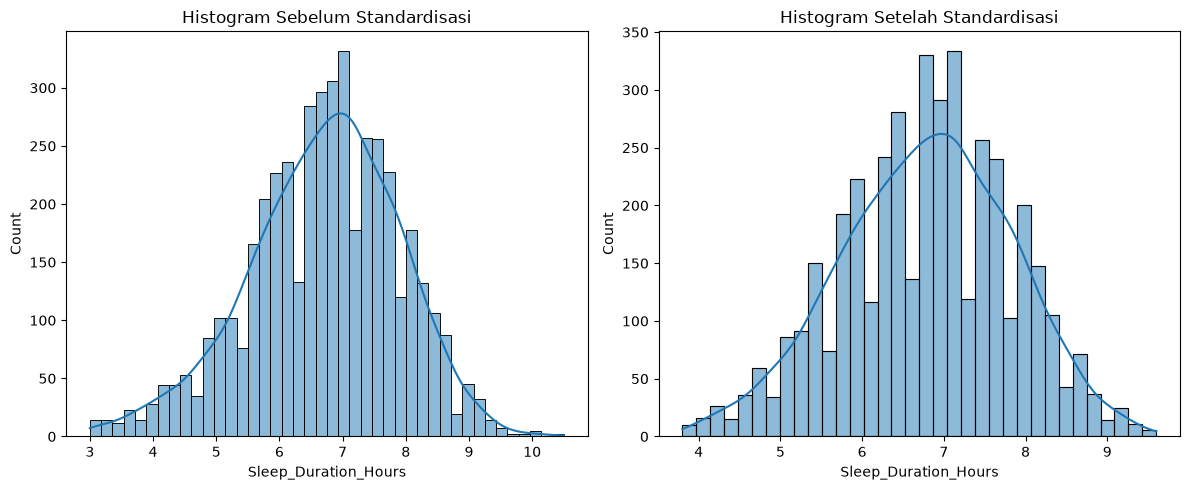

In [29]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(social_media[numeric_features[3]], kde=True)
plt.title("Histogram Sebelum Standardisasi")

plt.subplot(1, 2, 2)
sns.histplot(df[numeric_features[3]], kde=True)
plt.title("Histogram Setelah Standardisasi")

plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 5)) membuat gambar berukuran 12 × 5. plt.subplot(1, 2, 1) menyiapkan grafik pertama, social_media[numeric features[3]] mengambil satu kolom numerik dari data sebelum penyaringan outlier, sns.histplot(..., kde=True) membuat histogram beserta kurva distribusi, Grafik kedua menggunakan kolom yang sama dari df, yaitu data setelah penyaringan outlier, plt.tight_layout() mengatur jarak antargrafik. plt.show() menampilkan hasil.
Output berupa dua histogram berdampingan, histogram Sebelum Standardisasi: distribusi kolom dari social_media, histogram Setelah Standardisasi: distribusi kolom dari df setelah proses sebelumnya.


# 10. DATA SPLITTING

# 10.1 Memisahkan fitur X dan target y

In [30]:
X = df_lencoder.drop(columns=['Mental_Health_Index'])
y = df_lencoder['Mental_Health_Index']

X: fitur atau variabel yang digunakan untuk membuat prediksi.
y: target atau nilai yang ingin diprediksi.


# 10.2 Membagi data training dan testing

In [31]:
x_train, x_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=1
)

Fungsi train_test_split() membagi fitur dan target secara bersamaan agar pasangan datanya tetap sesuai. X: seluruh fitur, y: target indeks kesehatan mental.test_size=0.2: 20% data dialokasikan untuk pengujian. random_state=1: mengatur nilai acak agar pembagian dapat direproduksi jika data dan lingkungan tetap sama. Hasilnya: x_train: fitur untuk melatih model, x_test: fitur untuk menguji model. y_train: target untuk melatih model, y_test: target sebenarnya untuk pengujian.

# 10.3 Menampilkan jumlah data

In [32]:
print("Jumlah data:", len(X))
print("Jumlah data latih:", len(x_train))
print("Jumlah data test:", len(x_test))

Jumlah data: 4122
Jumlah data latih: 3297
Jumlah data test: 825


Sebanyak 3.297 baris digunakan untuk mempelajari pola data, sedangkan 825 baris digunakan untuk mengevaluasi prediksi pada data yang tidak digunakan dalam proses training tersebut. Jumlah training dan testing sesuai dengan total data 3297+825=4122.

# 11. MODEL TRAINING

In [33]:
clf = tree.DecisionTreeRegressor()

clf.fit(x_train, y_train)

,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"max_leaf_node

Kode membuat objek model regresi berbasis pohon keputusan. Decision Tree Regressor mempelajari aturan pemisahan data berdasarkan fitur. Data kemudian dibagi menjadi kelompok-kelompok yang lebih homogen terhadap nilai target. 
ontoh konseptual aturan yang mungkin dipelajari model: Jika durasi tidur berada di rentang tertentu, lanjutkan ke cabang berikutnya, Jika penggunaan media sosial melebihi nilai tertentu, periksa fitur lainnya. Setelah mencapai daun pohon, model memberikan nilai prediksi. Metode .fit() melatih model dengan memasangkan fitur training (x_train) dan target training (y_train). Model mencoba menemukan pola hubungan antara fitur yang diberikan dan indeks kesehatan mental. Sementara Output tersebut menunjukkan representasi objek estimator yang dikembalikan oleh .fit(). Ini bukan hasil prediksi dan bukan pula skor akurasi.


# 12. MODEL EVALUATION

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

y_pred = clf.predict(x_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MAE: 6.276363636363636
MSE: 62.81212121212121
R2 Score: 0.4653837159717732



Evaluasi model bertujuan mengukur kualitas prediksi pada data testing yang tidak dipakai untuk melatih model. Untuk menghitung prediksi, Model menerima fitur dari data testing dan menghasilkan prediksi indeks kesehatan mental. Hasil prediksi disimpan pada variabel y_pred. Untuk Mean Absolute Error (MAE), MAE menghitung rata-rata selisih absolut antara nilai sebenarnya dan prediksi
MAE=1/n ∑_(i=1)^n▒∣ y_i-y ̂_i∣

Semakin kecil MAE, semakin dekat prediksi model dengan nilai sebenarnya secara rata-rata. Mean Squared Error (MSE),  MSE menghitung rata-rata kuadrat selisih antara nilai sebenarnya dan prediksi.
MSE=1/n ∑_(i=1)^n▒( ├ y_i-y ̂_i ├ )┤^2 ┤
Karena selisih dikuadratkan, kesalahan besar mendapat penalti lebih besar. Nilai MSE tidak berada pada satuan yang sama dengan target, melainkan satuan target yang dikuadratkan. Lalu R² mengukur seberapa baik model menjelaskan variasi target dibandingkan prediksi dasar yang menggunakan rata-rata target pada data pengujian.
R^2=1-(∑▒( ├ y_i-y ̂_i ├ )┤^2 ┤)/(∑▒( ├ y_i-y ̅├ )┤^2 ┤ )
R² dapat bernilai 1 untuk prediksi sempurna, 0 untuk model yang setara dengan prediksi rata-rata dalam kondisi evaluasi standar, dan negatif jika model lebih buruk daripada prediksi rata-rata.
Interpretasi hasil
MAE = 6,3964
Secara rata-rata, selisih absolut antara prediksi model dan nilai sebenarnya adalah sekitar 6,40 poin indeks kesehatan mental. Apakah nilai ini cukup baik bergantung pada rentang dan konteks skor target.
MSE = 65,6497
Nilai ini merupakan rata-rata kesalahan yang dikuadratkan. MSE tidak boleh langsung dibaca sebagai rata-rata kesalahan sebesar 65 poin. Akar kuadrat MSE menghasilkan RMSE sekitar 8,10 poin.
R² = 0,4412
Pada data testing, model memiliki R² sekitar 0,441 atau 44,12%. Artinya, model memberikan peningkatan penjelasan variasi target dibandingkan prediksi rata-rata, tetapi masih menyisakan sebagian besar variasi yang belum dijelaskan oleh prediksi model.
R² sebesar 0,441 tidak berarti akurasi klasifikasi sebesar 44,12%, karena model ini adalah model regresi.
Apakah hasilnya sudah baik? Hasil tersebut memberikan gambaran awal kemampuan model, tetapi belum cukup untuk menyatakan bahwa model sudah optimal. Perlu dilakukan perbandingan dengan model dasar, pengaturan parameter pohon, pemeriksaan kebocoran fitur, dan evaluasi yang konsisten.


# 13. CROSS-VALIDATION

In [34]:
scores = cross_val_score(clf,X,y,cv=5,scoring='r2')

print("Skor setiap fold:")

for i, score in enumerate(scores, 1):
    print(f"Fold {i}: {score:.4f}")

print(f"\nRata-rata R²: {scores.mean():.4f}")

Skor setiap fold:
Fold 1: 0.4058
Fold 2: 0.4116
Fold 3: 0.4214
Fold 4: 0.4338
Fold 5: 0.3627

Rata-rata R²: 0.4071


clf adalah model Decision Tree Regressor, X dan y merupakan fitur dan target, cv=5 meminta pembagian menjadi lima fold, scoring='r2' menentukan bahwa metrik evaluasi yang dihitung adalah R². Pada setiap putaran, model dilatih menggunakan empat fold dan dievaluasi pada fold yang tersisa. Proses dilakukan lima kali sehingga setiap fold mendapat giliran menjadi bagian evaluasi. Perulangan menampilkan nomor fold dan skor R² hingga empat angka di belakang koma. Kode menghitung rata-rata skor dari kelima fold untuk memberikan ringkasan performa model. Fold 3 memiliki skor tertinggi, yaitu 0,4499, Fold 5 memiliki skor terendah, yaitu 0,3121 dan Rata-rata kelima fold adalah 0,3986.
Skor yang berbeda menunjukkan bahwa performa model berubah menurut pembagian data. Fold 5 memberikan hasil lebih rendah dibandingkan empat fold lainnya, sehingga ada kemungkinan model kurang konsisten pada bagian data tertentu.
